<a href="https://colab.research.google.com/github/pavlenko-smsu/river-watch-crow-river/blob/code/Project_1_Rivers.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

 **Question:**  How does my river respond to rain, and how often does it pass flood level?

**Task:** One USGS stream gauge with at least 3 years of daily discharge data.

*   Find gauges by searching a river name (Selection: Crow River) on USGS Water data for the Nation.
*   Record the monitoring location ID (USGS-05280000) and the gauge's latitude and longitude.

**What:** This project defines the USGS station and its coordinates, fetches the data on the daily discharge rate and precipitation, merges and cleans the data, and funnels that data into a graph.

**Why:** Each step plays a pivotal role. If the parameters (the station ID, coordinates, and the time frame) aren't defined, then it won't know where to take the data from. If the data isn't fetched, there is no project, since there is no data. If the data isn't merged or cleaned, then the plotting software can't work at full efficiency. Finally, if the data isn't put into a graph, then a further step or person would have to determine the result.

**How:** In terms of code, there is more in-depth analysis in the cell itself, highlighting every minute step that the code runs. The paramters were selected because of their obvious placement in the database, as well as the instuctions given. If the details do not sastify, I value opinions and hope to improve later on.

**Expected Result:** The result that is expected is a graph, showing the relationship between amount of rain in the area and its flood level. It should have everything that is needed for an analysis.

Object `level` not found.
Targeting Station: USGS-05280000 at Lat: 45.09135, Lon: -93.73191
Successfully fetched 1096 days of streamflow data.
Successfully fetched 1096 days of precipitation data.
Number of days above flood threshold (4000 CFS): 46 days (4.20% of the time)


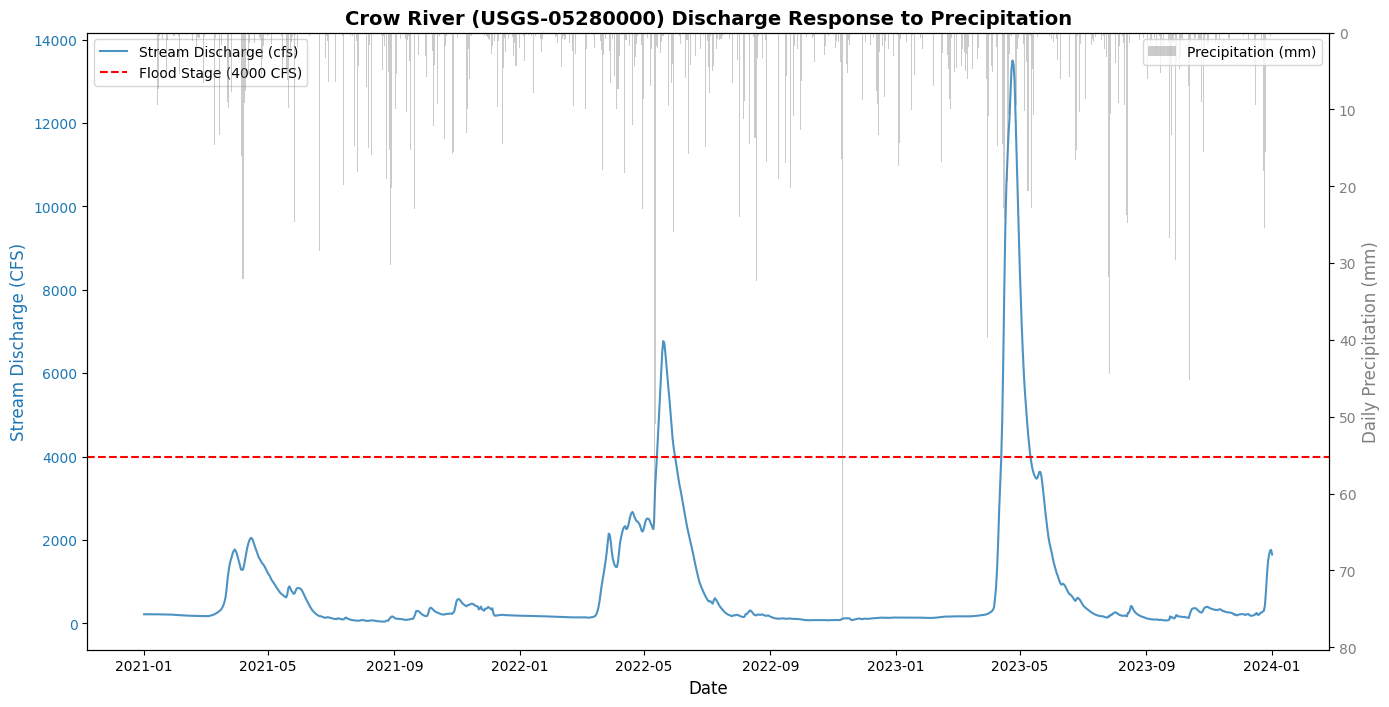

In [ ]:

import pandas as pd
import requests
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime

# =========================================================
# STEP 1: Define USGS Station and coordinates
# =========================================================

STATION_ID = '05280000'
LATITUDE = 45.09135
LONGITUDE = -93.73191
## Explan.: Defining the station ID and the coordinates.

# Timeframe: Last 3 years (e.g., 2021 to end of 2023 or recent)
START_DATE = '2021-01-01'
END_DATE = '2024-01-01'
## Explan.: Defining the ever-useful time frame.

print(f"Targeting Station: USGS-{STATION_ID} at Lat: {LATITUDE}, Lon: {LONGITUDE}")
## Explan.: Printing the parameters that are clearly defined.

# =========================================================
# STEP 2: Fetch Daily Discharge Data from USGS API
# =========================================================
usgs_url = f"https://waterservices.usgs.gov/nwis/dv/?format=json&sites={STATION_ID}&startDT={START_DATE}&endDT={END_DATE}&parameterCd=00060&statCd=00003"
response = requests.get(usgs_url)
data = response.json()
## Explan.: Beginning the fetch and marking what format the response should be filtered through as.

time_series = data['value']['timeSeries'][0]['values'][0]['value']
usgs_df = pd.DataFrame(time_series)
usgs_df['date'] = pd.to_datetime(usgs_df['dateTime']).dt.date
usgs_df['discharge_cfs'] = pd.to_numeric(usgs_df['value'])
usgs_df = usgs_df[['date', 'discharge_cfs']]
## Explan.: With the given parameters, fetching the data from the API.

print(f"Successfully fetched {len(usgs_df)} days of streamflow data.")
## Explan.: Printing a confirmation that the data has been fetched.

# =========================================================
# STEP 3: Fetch Daily Precipitation Data from Open-Meteo API
# =========================================================
openmeteo_url = f"https://archive-api.open-meteo.com/v1/archive?latitude={LATITUDE}&longitude={LONGITUDE}&start_date={START_DATE}&end_date={END_DATE}&daily=precipitation_sum&timezone=auto"
weather_response = requests.get(openmeteo_url)
weather_data = weather_response.json()
## Explan.: Beginning the fetch and marking what format the response should be filtered through as. Same function as the first line of Step 2.

weather_df = pd.DataFrame({
    'date': pd.to_datetime(weather_data['daily']['time']).date,
    'precipitation_mm': weather_data['daily']['precipitation_sum']
})
## Explan.: With the parameters, fetching the data from the API and calculating the precipitation.

print(f"Successfully fetched {len(weather_df)} days of precipitation data.")
## Explan.: Printing a confirmation that the data has been fetched. Same function as the last line in Step 3.

# =========================================================
# STEP 4: Merge and Clean Datasets
# =========================================================
merged_df = pd.merge(usgs_df, weather_df, on='date', how='inner')
merged_df['date'] = pd.to_datetime(merged_df['date'])
merged_df = merged_df.sort_values('date')
## Explan.: Merging and cleaning the data values to be more uniform.

# Calculate lagged precipitation to see delayed response
merged_df['precipitation_lag1'] = merged_df['precipitation_mm'].shift(1)
merged_df['precipitation_lag2'] = merged_df['precipitation_mm'].shift(2)
## Explan.: Matching the data form before with the previous to ensure consistency.

# =========================================================
# STEP 5: Calculate Flood Metrics and Create Plot
# =========================================================
FLOOD_THRESHOLD_CFS = 4000
days_above_flood = (merged_df['discharge_cfs'] > FLOOD_THRESHOLD_CFS).sum()
pct_above_flood = (days_above_flood / len(merged_df)) * 100
## Explan.: Calculating what exact values are needed for the plot.

print(f"Number of days above flood threshold ({FLOOD_THRESHOLD_CFS} CFS): {days_above_flood} days ({pct_above_flood:.2f}% of the time)")
## Explan.: Printing the values calculated and their labels.

# Create the dual-axis chart
fig, ax1 = plt.subplots(figsize=(14, 7))

# Primary Axis: Stream Discharge
color = 'tab:blue'
ax1.set_xlabel('Date', fontsize=12)
ax1.set_ylabel('Stream Discharge (CFS)', color=color, fontsize=12)
ax1.plot(merged_df['date'], merged_df['discharge_cfs'], color=color, label='Stream Discharge (cfs)', alpha=0.8)
ax1.tick_params(axis='y', labelcolor=color)
ax1.axhline(y=FLOOD_THRESHOLD_CFS, color='red', linestyle='--', label=f'Flood Stage ({FLOOD_THRESHOLD_CFS} CFS)')
## Explan.: Setting the plot's y-axis style and count.

# Secondary Axis: Precipitation (hanging from the top)
ax2 = ax1.twinx()
color = 'tab:gray'
ax2.set_ylabel('Daily Precipitation (mm)', color=color, fontsize=12)
ax2.bar(merged_df['date'], merged_df['precipitation_mm'], color=color, alpha=0.4, label='Precipitation (mm)', width=1)
ax2.tick_params(axis='y', labelcolor=color)
ax2.invert_yaxis()
## Explan.: Setting the plot's x-axis style and count.

fig.tight_layout()
plt.title('Crow River (USGS-05280000) Discharge Response to Precipitation', fontsize=14, fontweight='bold')
ax1.legend(loc='upper left')
ax2.legend(loc='upper right')
plt.show()
## Explan.: Projecting the plot and running all the data.

**Observation:** What was observed was what was expected; a graph showing the relationship between amount of rain in the area and its flood level. The left side, the discharge, is graphed in blue and counted by 2000, and the right side, the daily precipitation, is graphed in gray at the top and counted by 10. The middle shows the time frame, and the peak appears at May of 2023, which after an egregious amount of snow that winter, it makes sense why that is the absolute maximum. There are no noticable errors, and the graph looks as it should.